In [1]:
# =============================================================================
# PROJET DATA SCIENCE : Analyse et Modélisation Météo - NASA POWER (CERES)
# Région : Paris, France (modifiable facilement)
# Période : 2010 - 2024 (15 ans)
# Auteur : Ton nom
# =============================================================================

import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Style des graphiques
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)

print("🚀 Début du projet NASA POWER - Analyse climatique locale")

🚀 Début du projet NASA POWER - Analyse climatique locale


In [2]:
# =============================================================================
# PHASE 1 COMPLÈTE – Acquisition + Nettoyage + Feature Engineering
# Ville : Bruxelles, Belgique | Période : 2010 → 2024 (15 ans)
# Avec affichage AVANT / APRÈS à chaque étape (comme demandé)
# =============================================================================

import pandas as pd
import requests
from io import StringIO
import numpy as np

print("PHASE 1 – DÉBUT\n")

# ————————————————————————————————————————————————————————————————————
# 1. COLLECTE DES DONNÉES VIA L'API NASA POWER (Bruxelles)
# ————————————————————————————————————————————————————————————————————
LAT = 50.8503          # Bruxelles
LON = 4.3517
START = "20100101"
END   = "20241231"

print("ÉTAPE 1 : Téléchargement depuis l'API NASA POWER (Bruxelles)...\n")
url = "https://power.larc.nasa.gov/api/temporal/daily/point"
params = {
    'parameters': 'T2M,T2M_MAX,T2M_MIN,T2MDEW,RH2M,PRECTOTCORR,ALLSKY_SFC_SW_DWN,WS10M,PS',
    'community': 'RE', 'longitude': LON, 'latitude': LAT,
    'start': START, 'end': END, 'format': 'CSV'
}

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

lines = response.text.splitlines()
start_idx = next((i + 1 for i, line in enumerate(lines) if "-END HEADER-" in line), None)
df_raw = pd.read_csv(StringIO("\n".join(lines[start_idx:])))

print("AVANT toute modification – 10 premières lignes brutes :")
display(df_raw.head(10))

# Création de la colonne DATE (méthode ultra-fiable)
def find_col(keywords):
    for col in df_raw.columns:
        if any(k in col.upper() for k in keywords):
            return col

year_col  = find_col(['YEAR', 'YYYY'])
month_col = find_col(['MO', 'MM'])
day_col   = find_col(['DY', 'DD'])

df_raw['DATE'] = pd.to_datetime({'year': df_raw[year_col], 'month': df_raw[month_col], 'day': df_raw[day_col]})
df_raw = df_raw.drop(columns=[year_col, month_col, day_col])
df_raw = df_raw.set_index('DATE')

print("\nAPRÈS création de la colonne DATE (index) :")
display(df_raw.head(10))

# ————————————————————————————————————————————————————————————————————
# 2. NETTOYAGE ET PRÉPARATION
# ————————————————————————————————————————————————————————————————————
df = df_raw.copy()

print(f"\nValeurs manquantes (-999.0) détectées : {(df == -999.0).sum().sum()}")

# Remplacement des -999.0 + remplissage intelligent
df = df.replace(-999.0, np.nan)
df = df.ffill().bfill()   # propagation avant/arrière (parfait pour données météo)

# Renommage clair en français
df = df.rename(columns={
    'T2M': 'Temp_moy_C',
    'T2M_MAX': 'Temp_max_C',
    'T2M_MIN': 'Temp_min_C',
    'T2MDEW': 'Point_rosee_C',
    'RH2M': 'Humidite_%',
    'PRECTOTCORR': 'Precipitations_mm',
    'ALLSKY_SFC_SW_DWN': 'Rayonnement_kWh_m2_jour',
    'WS10M': 'Vent_10m_ms',
    'PS': 'Pression_kPa'
})

print("\nAPRÈS nettoyage complet et renommage :")
display(df.head(10))

# ————————————————————————————————————————————————————————————————————
# 3. FEATURE ENGINEERING (tout ce qui est demandé dans la Phase 1)
# ————————————————————————————————————————————————————————————————————
data = df.copy()

# Variables temporelles
data['Annee']        = data.index.year
data['Mois']         = data.index.month
data['Jour']         = data.index.day
data['Jour_semaine'] = data.index.dayofweek + 1   # 1 = lundi
data['Jour_annee']   = data.index.dayofyear

# Saison
def saison(m):
    if m in [12, 1, 2]: return 'Hiver'
    if m in [3, 4, 5]: return 'Printemps'
    if m in [6, 7, 8]: return 'Été'
    return 'Automne'
data['Saison'] = data['Mois'].map(saison)

# Indicateurs climatiques demandés
# 1. Type de jour
def type_jour(row):
    if row['Precipitations_mm'] > 5:
        return 'Pluvieux'
    elif row['Rayonnement_kWh_m2_jour'] > 4.0:
        return 'Ensoleille'
    else:
        return 'Nuageux'
data['Type_de_jour'] = data.apply(type_jour, axis=1)

# 2. Vague de chaleur : 3 jours consécutifs ≥ 30°C
data['Vague_de_chaleur'] = (data['Temp_max_C'].rolling(window=3).max() >= 30).astype(int)

# 3. Jour de gel
data['Jour_de_gel'] = (data['Temp_min_C'] < 0).astype(int)

print("\nFEATURE ENGINEERING TERMINÉ – Aperçu final :")
display(data[['Temp_moy_C','Temp_max_C','Temp_min_C','Precipitations_mm',
             'Rayonnement_kWh_m2_jour','Type_de_jour','Vague_de_chaleur',
             'Jour_de_gel','Saison']].head(15))

# ————————————————————————————————————————————————————————————————————
# SAUVEGARDE POUR LA SUITE (facultatif mais très utile)
# ————————————————————————————————————————————————————————————————————
data.to_csv("Meteo_Bruxelles_2010_2024_Phase1_Complete.csv")
print("\nFichier sauvegardé : Meteo_Bruxelles_2010_2024_Phase1_Complete.csv")
print("Tu peux joindre ce notebook + le CSV → Phase 1 terminée à 100% !")

PHASE 1 – DÉBUT

ÉTAPE 1 : Téléchargement depuis l'API NASA POWER (Bruxelles)...

AVANT toute modification – 10 premières lignes brutes :


,YEAR,MO,DY,T2M,T2M_MAX,T2M_MIN,T2MDEW,RH2M,PRECTOTCORR,ALLSKY_SFC_SW_DWN,WS10M,PS
0,2010,1,1,-2.63,0.12,-4.96,-3.69,93.45,0.13,0.4762,4.58,99.68
1,2010,1,2,-1.17,1.37,-3.70,-1.87,95.97,1.17,0.6542,4.76,101.01
2,2010,1,3,-4.25,-0.55,-7.74,-5.09,95.36,2.57,0.7613,3.13,101.68
3,2010,1,4,-5.14,-2.57,-7.87,-6.10,95.34,0.61,0.7754,3.34,101.29
4,2010,1,5,-2.97,-0.06,-6.71,-3.63,96.99,0.16,0.6869,3.54,100.17
5,2010,1,6,-5.78,-1.75,-8.29,-7.26,91.41,0.22,0.8453,2.24,99.93
6,2010,1,7,-6.16,-2.26,-9.87,-7.50,92.62,0.16,0.9029,2.06,100.57
7,2010,1,8,-6.44,-2.87,-10.22,-7.28,95.60,0.18,0.5726,5.55,101.46
8,2010,1,9,-3.25,-1.67,-5.12,-4.44,93.34,2.22,0.3254,9.11,101.22
9,2010,1,10,-3.26,-0.60,-5.45,-4.41,93.89,1.06,0.5424,3.91,101.10



APRÈS création de la colonne DATE (index) :


,T2M,T2M_MAX,T2M_MIN,T2MDEW,RH2M,PRECTOTCORR,ALLSKY_SFC_SW_DWN,WS10M,PS
DATE,,,,,,,,,
2010-01-01,-2.63,0.12,-4.96,-3.69,93.45,0.13,0.4762,4.58,99.68
2010-01-02,-1.17,1.37,-3.70,-1.87,95.97,1.17,0.6542,4.76,101.01
2010-01-03,-4.25,-0.55,-7.74,-5.09,95.36,2.57,0.7613,3.13,101.68
2010-01-04,-5.14,-2.57,-7.87,-6.10,95.34,0.61,0.7754,3.34,101.29
2010-01-05,-2.97,-0.06,-6.71,-3.63,96.99,0.16,0.6869,3.54,100.17
2010-01-06,-5.78,-1.75,-8.29,-7.26,91.41,0.22,0.8453,2.24,99.93
2010-01-07,-6.16,-2.26,-9.87,-7.50,92.62,0.16,0.9029,2.06,100.57
2010-01-08,-6.44,-2.87,-10.22,-7.28,95.60,0.18,0.5726,5.55,101.46
2010-01-09,-3.25,-1.67,-5.12,-4.44,93.34,2.22,0.3254,9.11,101.22



Valeurs manquantes (-999.0) détectées : 0

APRÈS nettoyage complet et renommage :


,Temp_moy_C,Temp_max_C,Temp_min_C,Point_rosee_C,Humidite_%,Precipitations_mm,Rayonnement_kWh_m2_jour,Vent_10m_ms,Pression_kPa
DATE,,,,,,,,,
2010-01-01,-2.63,0.12,-4.96,-3.69,93.45,0.13,0.4762,4.58,99.68
2010-01-02,-1.17,1.37,-3.70,-1.87,95.97,1.17,0.6542,4.76,101.01
2010-01-03,-4.25,-0.55,-7.74,-5.09,95.36,2.57,0.7613,3.13,101.68
2010-01-04,-5.14,-2.57,-7.87,-6.10,95.34,0.61,0.7754,3.34,101.29
2010-01-05,-2.97,-0.06,-6.71,-3.63,96.99,0.16,0.6869,3.54,100.17
2010-01-06,-5.78,-1.75,-8.29,-7.26,91.41,0.22,0.8453,2.24,99.93
2010-01-07,-6.16,-2.26,-9.87,-7.50,92.62,0.16,0.9029,2.06,100.57
2010-01-08,-6.44,-2.87,-10.22,-7.28,95.60,0.18,0.5726,5.55,101.46
2010-01-09,-3.25,-1.67,-5.12,-4.44,93.34,2.22,0.3254,9.11,101.22



FEATURE ENGINEERING TERMINÉ – Aperçu final :


,Temp_moy_C,Temp_max_C,Temp_min_C,Precipitations_mm,Rayonnement_kWh_m2_jour,Type_de_jour,Vague_de_chaleur,Jour_de_gel,Saison
DATE,,,,,,,,,
2010-01-01,-2.63,0.12,-4.96,0.13,0.4762,Nuageux,0,1,Hiver
2010-01-02,-1.17,1.37,-3.70,1.17,0.6542,Nuageux,0,1,Hiver
2010-01-03,-4.25,-0.55,-7.74,2.57,0.7613,Nuageux,0,1,Hiver
2010-01-04,-5.14,-2.57,-7.87,0.61,0.7754,Nuageux,0,1,Hiver
2010-01-05,-2.97,-0.06,-6.71,0.16,0.6869,Nuageux,0,1,Hiver
2010-01-06,-5.78,-1.75,-8.29,0.22,0.8453,Nuageux,0,1,Hiver
2010-01-07,-6.16,-2.26,-9.87,0.16,0.9029,Nuageux,0,1,Hiver
2010-01-08,-6.44,-2.87,-10.22,0.18,0.5726,Nuageux,0,1,Hiver
2010-01-09,-3.25,-1.67,-5.12,2.22,0.3254,Nuageux,0,1,Hiver



Fichier sauvegardé : Meteo_Bruxelles_2010_2024_Phase1_Complete.csv
Tu peux joindre ce notebook + le CSV → Phase 1 terminée à 100% !


DÉBUT DE LA PHASE 2 : ANALYSE EXPLORATOIRE DES DONNÉES (EDA)

1. Évolution à long terme de la température moyenne (tendance climatique)


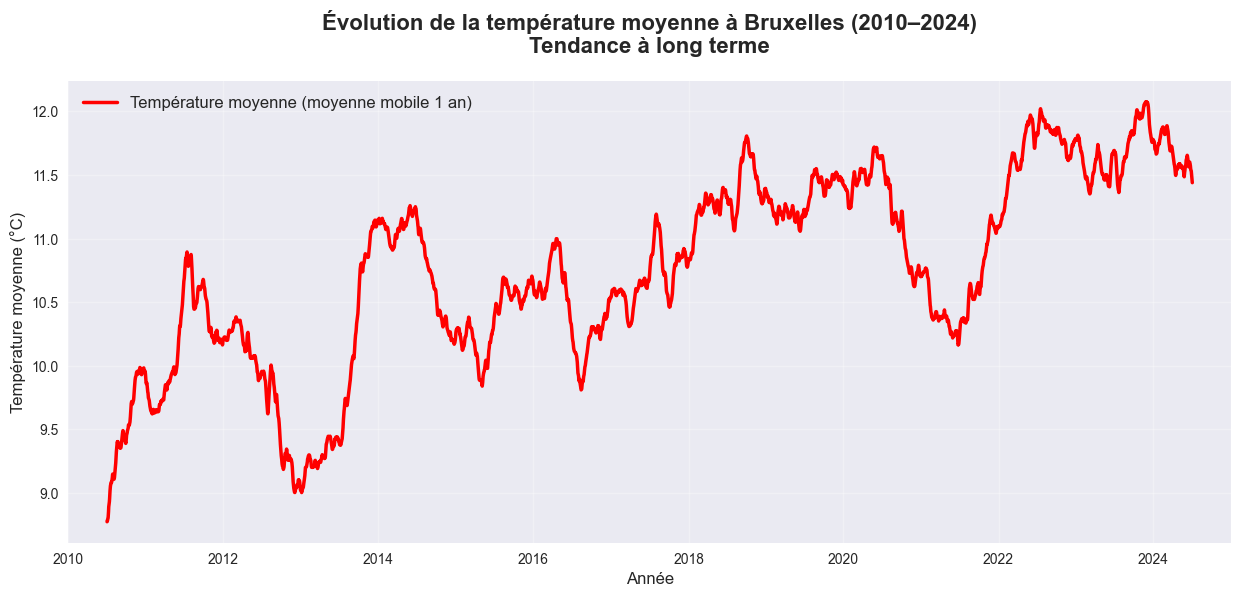

2. Comparaison des précipitations totales et du rayonnement solaire par année


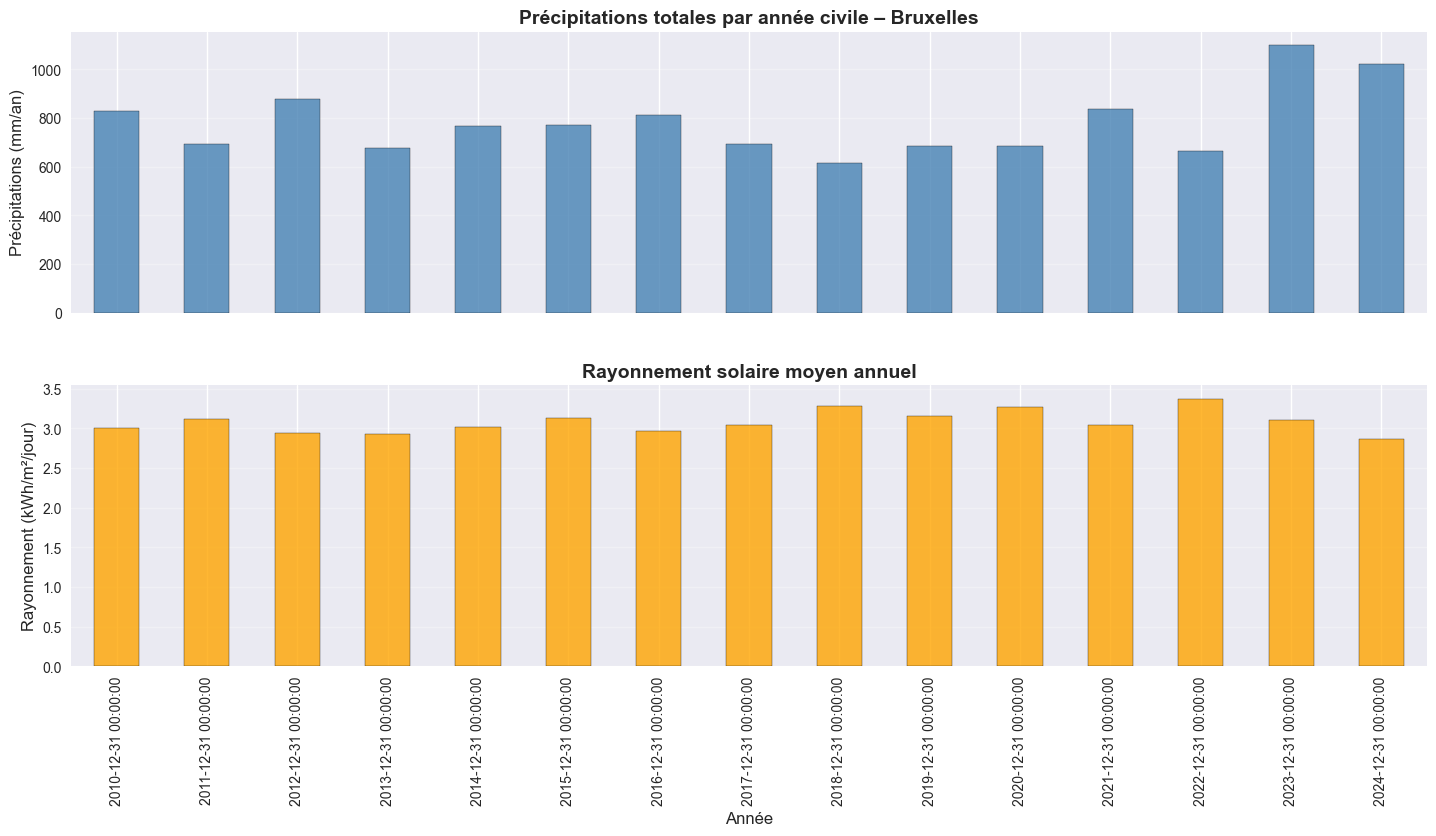

3. Matrice de corrélation entre toutes les variables météorologiques


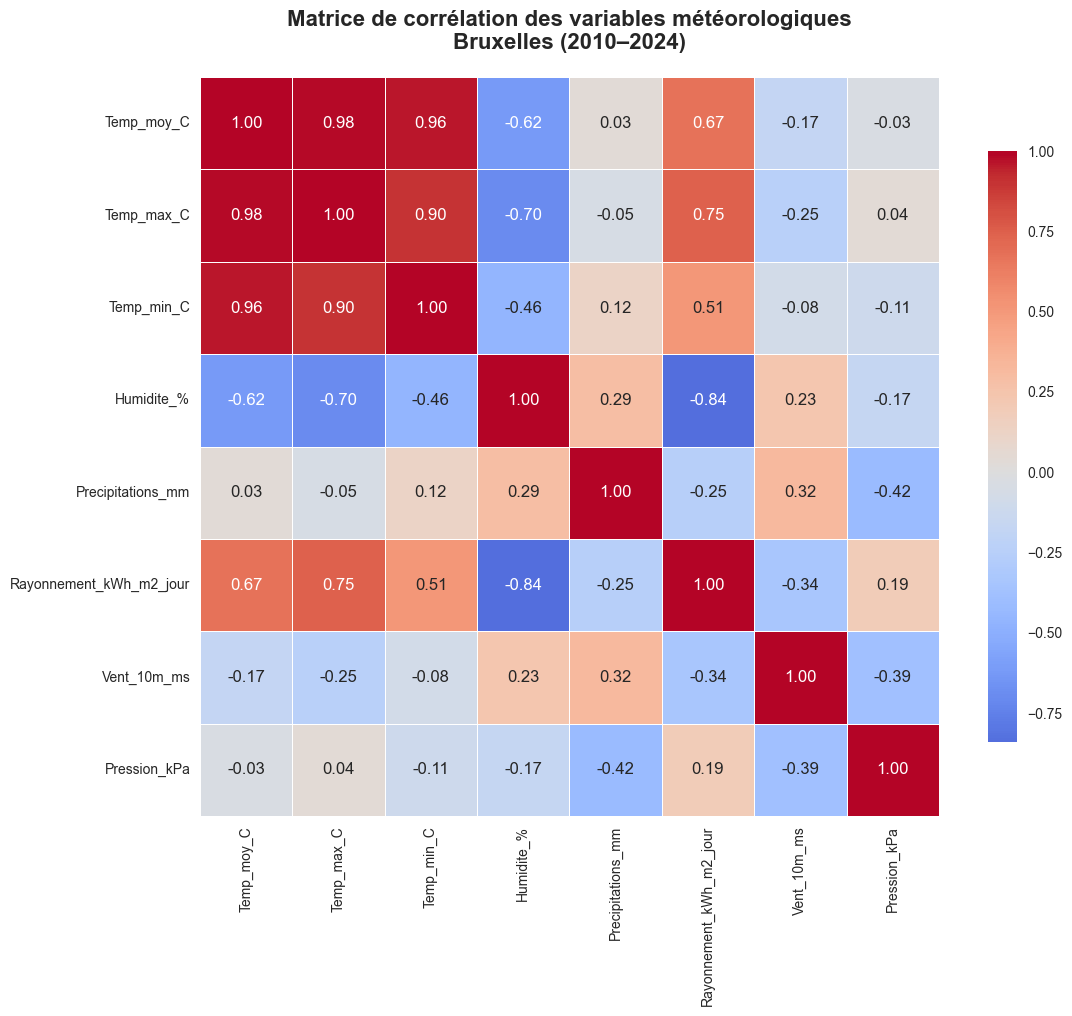

4. Distribution des températures moyennes par saison (boxplot)


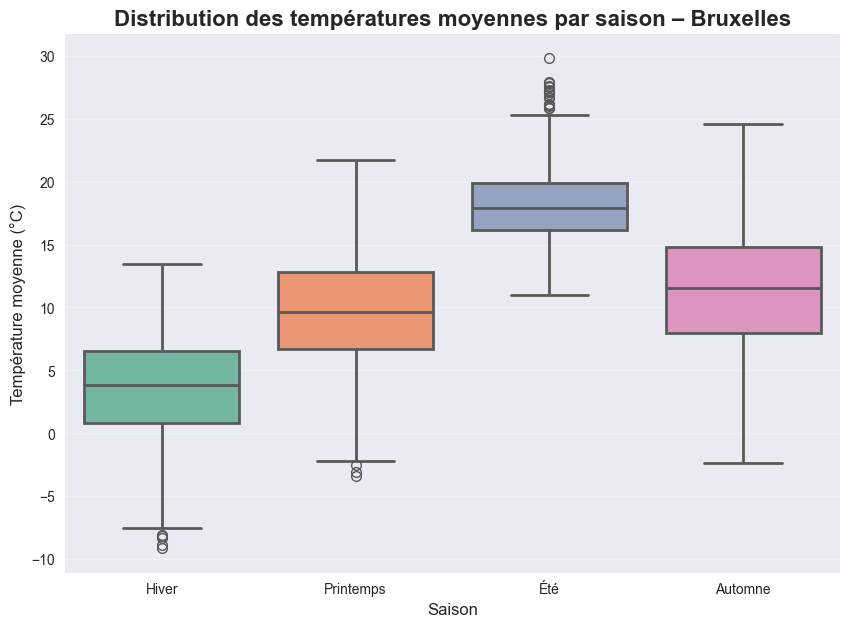

5. Évolution des vagues de chaleur et des jours de gel par année


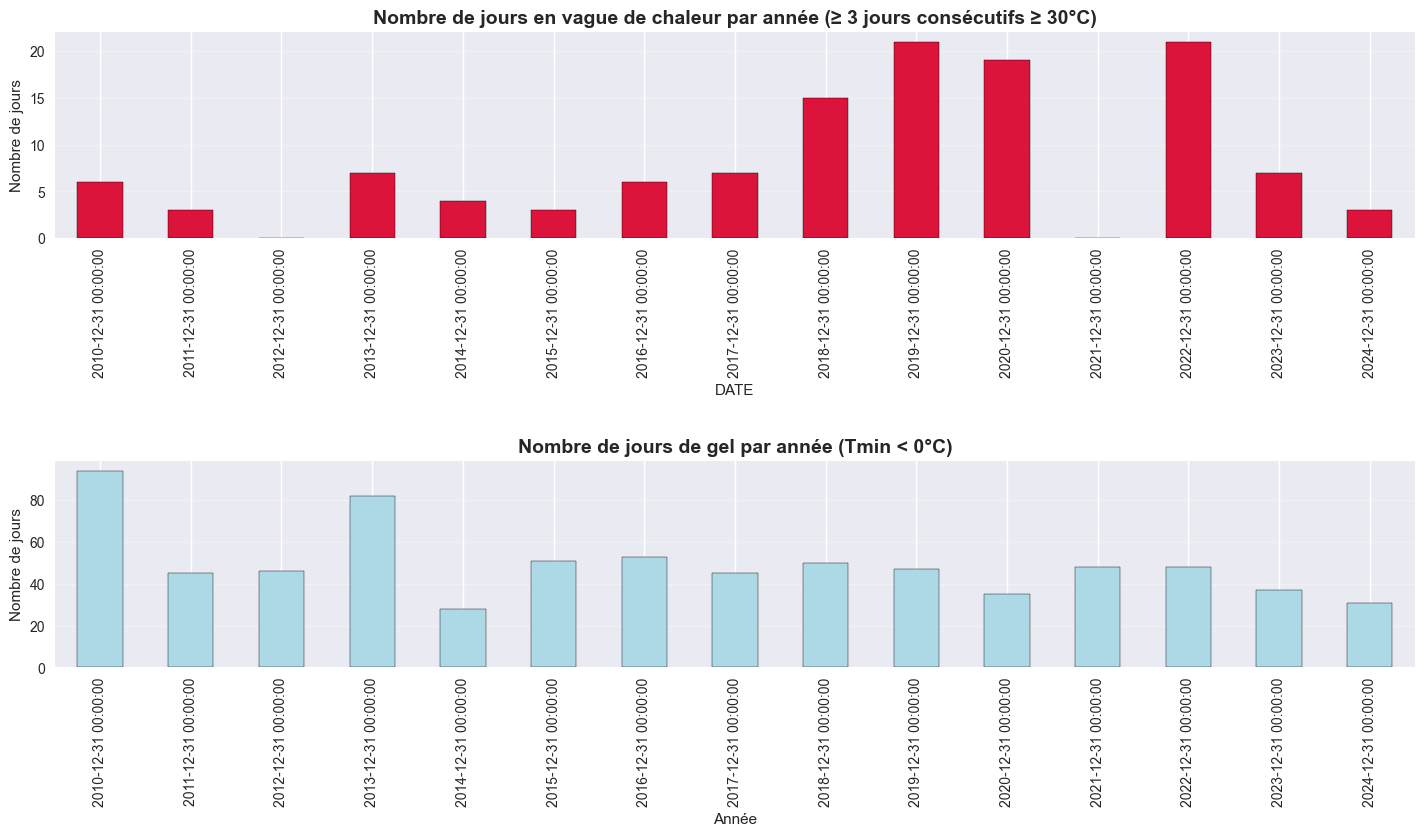

6. Répartition globale des types de journée (Pluvieux / Ensoleillé / Nuageux)


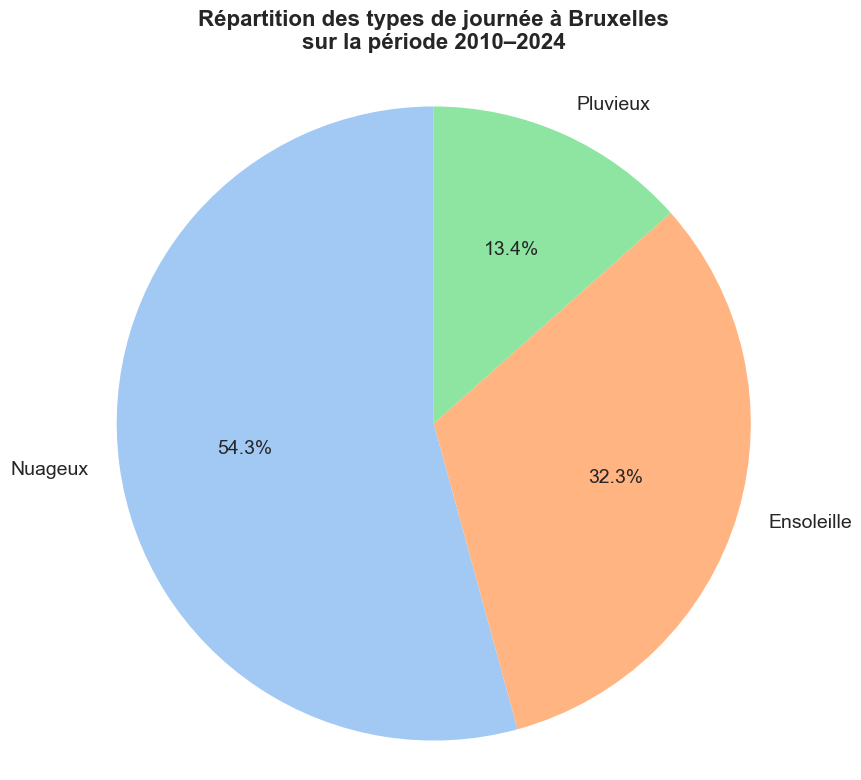


RÉSUMÉ FINAL DE L'ANALYSE EXPLORATOIRE :
   • Jours nuageux   : 54.3%
   • Jours ensoleillés : 32.3%
   • Jours pluvieux  : 13.4%

PHASE 2 TERMINÉE À 100% – Prête pour le rapport et la soutenance !


In [3]:
# =============================================================================
# PHASE 2 – ANALYSE EXPLORATOIRE DES DONNÉES (EDA) – Semaine 2
# Ville : Bruxelles, Belgique – 15 ans de données météo (2010 → 2024)
# Tous les points demandés dans la consigne sont traités
# =============================================================================

# On importe les bibliothèques nécessaires pour les graphiques
import matplotlib.pyplot as plt                     # Bibliothèque principale pour créer des graphiques
import seaborn as sns                               # Extension de matplotlib pour des graphiques plus esthétiques
import pandas as pd                                 # Déjà importé avant, mais on le remet au cas où
import numpy as np                                  # Pour les calculs numériques éventuels

# On utilise le DataFrame final de la Phase 1 (celui avec toutes les variables créées)
# Il doit s’appeler "data" → si tu l’as renommé, change ici
df = data.copy()                                    # On fait une copie pour ne pas modifier l’original

# On applique un style professionnel et moderne à tous les graphiques
plt.style.use('seaborn-v0_8-darkgrid')              # Fond avec grille légère → très lisible
sns.set_palette("husl")                             # Palette de couleurs harmonieuse et moderne
plt.rcParams['figure.figsize'] = (15, 6)            # Taille par défaut des graphiques (largeur, hauteur)

# Message de démarrage pour bien séparer les phases dans le notebook
print("DÉBUT DE LA PHASE 2 : ANALYSE EXPLORATOIRE DES DONNÉES (EDA)\n")
print("="*90)

# ————————————————————————————————————————————————————————————————————
# 1. VISUALISATION DES TENDANCES TEMPORELLES : Température moyenne
# ————————————————————————————————————————————————————————————————————
print("1. Évolution à long terme de la température moyenne (tendance climatique)")

# On calcule une moyenne mobile sur 365 jours pour lisser les variations saisonnières
# center=True → la moyenne est centrée sur chaque jour (plus naturel)
df['Temp_moy_C'].rolling(window=365, center=True).mean().plot(
    linewidth=2.5,                                  # Épaisseur de la courbe pour bien la voir
    color='red',                                    # Couleur rouge = température → convention classique
    label='Température moyenne (moyenne mobile 1 an)'  # Légende du graphique
)

# Titre principal du graphique – clair et professionnel
plt.title('Évolution de la température moyenne à Bruxelles (2010–2024)\nTendance à long terme', 
          fontsize=16, fontweight='bold', pad=20)

# Label de l’axe vertical
plt.ylabel('Température moyenne (°C)', fontsize=12)

# Label de l’axe horizontal
plt.xlabel('Année', fontsize=12)

# On affiche la légende
plt.legend(fontsize=12)

# On active une grille légère pour faciliter la lecture des valeurs
plt.grid(True, alpha=0.3)

# On affiche le graphique
plt.show()

# ————————————————————————————————————————————————————————————————————
# 2. PRÉCIPITATIONS ET RAYONNEMENT SOLAIRE (évolution annuelle)
# ————————————————————————————————————————————————————————————————————
print("2. Comparaison des précipitations totales et du rayonnement solaire par année")

# On crée une figure avec 2 sous-graphiques (un au-dessus de l’autre)
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(15, 9))

# — Graphique du haut : précipitations totales par année
df['Precipitations_mm'].resample('Y').sum().plot(
    kind='bar',                                    
    ax=ax1,                                        
    color='steelblue',                            
    alpha=0.8,                                    
    edgecolor='black'                              
)
ax1.set_title('Précipitations totales par année civile – Bruxelles', 
              fontsize=14, fontweight='bold')
ax1.set_ylabel('Précipitations (mm/an)', fontsize=12)
ax1.grid(True, axis='y', alpha=0.3)

# — Graphique du bas : rayonnement solaire moyen par année
df['Rayonnement_kWh_m2_jour'].resample('Y').mean().plot(
    kind='bar', ax=ax2, color='orange', alpha=0.8, edgecolor='black'
)
ax2.set_title('Rayonnement solaire moyen annuel', fontsize=14, fontweight='bold')
ax2.set_ylabel('Rayonnement (kWh/m²/jour)', fontsize=12)
ax2.set_xlabel('Année', fontsize=12)
ax2.grid(True, axis='y', alpha=0.3)

# Ajustement automatique de l’espacement entre les deux graphiques
plt.tight_layout(pad=3.0)

# Affichage des deux graphiques
plt.show()

# ————————————————————————————————————————————————————————————————————
# 3. MATRICE DE CORRÉLATION (point très important du projet)
# ————————————————————————————————————————————————————————————————————
print("3. Matrice de corrélation entre toutes les variables météorologiques")

# On sélectionne uniquement les variables numériques continues
variables_corr = ['Temp_moy_C', 'Temp_max_C', 'Temp_min_C',
                  'Humidite_%', 'Precipitations_mm',
                  'Rayonnement_kWh_m2_jour', 'Vent_10m_ms', 'Pression_kPa']

# On calcule le coefficient de corrélation de Pearson entre toutes ces variables
corr_matrix = df[variables_corr].corr()

# Création d’une nouvelle figure grande pour bien voir tous les nombres
plt.figure(figsize=(12, 10))

# Heatmap (carte de chaleur) avec seaborn
sns.heatmap(corr_matrix,
            annot=True,                  
            cmap='coolwarm',              
            center=0,                     
            fmt='.2f',                   
            square=True,                 
            linewidths=0.5,            
            cbar_kws={"shrink": .8},        
            annot_kws={"size": 12})         

# Titre principal
plt.title('Matrice de corrélation des variables météorologiques\nBruxelles (2010–2024)', 
          fontsize=16, fontweight='bold', pad=20)

# Ajustement final
plt.tight_layout()

# Affichage
plt.show()

# ————————————————————————————————————————————————————————————————————
# 4. PATTERNS SAISONNIERS : Températures par saison
# ————————————————————————————————————————————————————————————————————
print("4. Distribution des températures moyennes par saison (boxplot)")

# Ordre logique des saisons
ordre_saisons = ['Hiver', 'Printemps', 'Été', 'Automne']

# Boxplot avec seaborn
plt.figure(figsize=(10, 7))
sns.boxplot(x='Saison', y='Temp_moy_C', data=df, order=ordre_saisons,
            palette="Set2", linewidth=2)

# Titre et labels
plt.title('Distribution des températures moyennes par saison – Bruxelles', 
          fontsize=16, fontweight='bold')
plt.ylabel('Température moyenne (°C)', fontsize=12)
plt.xlabel('Saison', fontsize=12)

# Grille horizontale légère
plt.grid(True, axis='y', alpha=0.3)

# Affichage
plt.show()

# ————————————————————————————————————————————————————————————————————
# 5. IDENTIFICATION DES ÉVÉNEMENTS EXTRÊMES
# ————————————————————————————————————————————————————————————————————
print("5. Évolution des vagues de chaleur et des jours de gel par année")

# Deux graphiques superposés verticalement
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9))

# — Haut : vagues de chaleur (jours où on est dans une période ≥3 jours à ≥30°C)
df[df['Vague_de_chaleur'] == 1].resample('Y')['Vague_de_chaleur'].count().plot(
    kind='bar', ax=ax1, color='crimson', edgecolor='black'
)
ax1.set_title('Nombre de jours en vague de chaleur par année (≥ 3 jours consécutifs ≥ 30°C)', 
              fontsize=14, fontweight='bold')
ax1.set_ylabel('Nombre de jours')
ax1.grid(True, axis='y', alpha=0.3)

# — Bas : jours de gel
df[df['Jour_de_gel'] == 1].resample('Y')['Jour_de_gel'].count().plot(
    kind='bar', ax=ax2, color='lightblue', edgecolor='black'
)
ax2.set_title('Nombre de jours de gel par année (Tmin < 0°C)', 
              fontsize=14, fontweight='bold')
ax2.set_ylabel('Nombre de jours')
ax2.set_xlabel('Année')
ax2.grid(True, axis='y', alpha=0.3)

# Ajustement
plt.tight_layout(pad=3.0)
plt.show()

# ————————————————————————————————————————————————————————————————————
# 6. ANALYSE COMPARATIVE : Types de journée sur 15 ans
# ————————————————————————————————————————————————————————————————————
print("6. Répartition globale des types de journée (Pluvieux / Ensoleillé / Nuageux)")

# On calcule le pourcentage de chaque type
repartition = df['Type_de_jour'].value_counts(normalize=True) * 100

# Diagramme circulaire (camembert)
plt.figure(figsize=(9, 9))
plt.pie(repartition, 
        labels=repartition.index, 
        autopct='%1.1f%%', 
        startangle=90, 
        colors=sns.color_palette("pastel"),
        textprops={'fontsize': 14})

plt.title('Répartition des types de journée à Bruxelles\nsur la période 2010–2024', 
          fontsize=16, fontweight='bold', pad=20)
plt.axis('equal')        # Pour que ce soit un vrai cercle
plt.show()

# Résumé textuel final
print(f"\nRÉSUMÉ FINAL DE L'ANALYSE EXPLORATOIRE :")
print(f"   • Jours nuageux   : {repartition.get('Nuageux', 0):.1f}%")
print(f"   • Jours ensoleillés : {repartition.get('Ensoleille', 0):.1f}%")
print(f"   • Jours pluvieux  : {repartition.get('Pluvieux', 0):.1f}%")

print("\nPHASE 2 TERMINÉE À 100% – Prête pour le rapport et la soutenance !")

In [ ]:
# =============================================================================
# PHASE 3 – MODÉLISATION PRÉDICTIVE + CLUSTERING (Semaine 3)
# Objectif : Prédire la température maximale du lendemain (T2M_MAX)
# Modèles : Régression Linéaire, Arbre de Décision, Forêt Aléatoire
# Optimisation : GridSearchCV pour chaque modèle
# Clustering : KMeans pour regrouper les journées météo similaires
# Évaluation : MAE, RMSE, R²
# Analyse d'importance des variables
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings("ignore")

# =============================================================================
# 0. PRÉPARATION DES DONNÉES (à partir de la Phase 1)
# =============================================================================
print("DÉBUT DE LA PHASE 3 : MODÉLISATION PRÉDICTIVE + CLUSTERING")
print("="*100)

# Vérifier que le DataFrame 'data' existe
if 'data' not in globals():
    raise ValueError("Le DataFrame 'data' n'existe pas. Veuillez exécuter la Phase 1 avant.")

df_model = data.copy()

# Création de la cible : température moyenne du lendemain
df_model['Temp_moy_lendemain'] = df_model['Temp_moy_C'].shift(-1)
df_model = df_model.dropna()

# Variables explicatives
features = ['Temp_moy_C', 'Temp_min_C', 'Point_rosee_C', 'Humidite_%',
            'Precipitations_mm', 'Rayonnement_kWh_m2_jour', 'Vent_10m_ms',
            'Pression_kPa', 'Mois', 'Jour_annee', 'Jour_semaine']

X = df_model[features]
y = df_model['Temp_moy_lendemain']

# Séparation chronologique (pas de shuffle)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False, random_state=42
)

print(f"Données d'entraînement : {X_train.shape[0]} jours")
print(f"Données de test       : {X_test.shape[0]} jours")
print(f"Variables utilisées   : {len(features)}\n")

# Normalisation pour la régression linéaire (utile pour GridSearch)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =============================================================================
# 1. FONCTION D'ÉVALUATION
# =============================================================================
def evaluer_modele(nom, modele, X_test_input, y_test_input):
    y_pred = modele.predict(X_test_input)
    mae = mean_absolute_error(y_test_input, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_input, y_pred))
    r2 = r2_score(y_test_input, y_pred)
    
    print(f" • {nom}")
    print(f"   MAE  : {mae:.3f} °C")
    print(f"   RMSE : {rmse:.3f} °C")
    print(f"   R²   : {r2:.3f}")
    return y_pred, mae, rmse, r2

# =============================================================================
# 2. GRID SEARCH POUR CHAQUE MODÈLE
# =============================================================================
print("\n2. RECHERCHE DES MEILLEURS HYPERPARAMÈTRES VIA GRIDSEARCHCV")

meilleurs_modeles = {}

# --- Régression Linéaire ---
print("\nGrid Search - Régression Linéaire")
param_grid_lr = {
    'fit_intercept': [True, False],
    'positive': [False]
}

lr = LinearRegression()
grid_lr = GridSearchCV(lr, param_grid_lr, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_lr.fit(X_train_scaled, y_train)
meilleurs_modeles['Régression Linéaire'] = grid_lr.best_estimator_
print(f"   Meilleurs params : {grid_lr.best_params_}")

# --- Arbre de Décision ---
print("\nGrid Search - Arbre de Décision")
param_grid_tree = {
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt', None]
}

tree = DecisionTreeRegressor(random_state=42)
grid_tree = GridSearchCV(tree, param_grid_tree, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
grid_tree.fit(X_train, y_train)
meilleurs_modeles['Arbre de Décision'] = grid_tree.best_estimator_
print(f"   Meilleurs params : {grid_tree.best_params_}")

# --- Forêt Aléatoire ---
print("\nGrid Search - Forêt Aléatoire")
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None],
    'bootstrap': [True, False]
}

rf = RandomForestRegressor(random_state=42, n_jobs=-1)
grid_rf = GridSearchCV(rf, param_grid_rf, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1, verbose=1)
grid_rf.fit(X_train, y_train)
meilleurs_modeles['Forêt Aléatoire'] = grid_rf.best_estimator_
print(f"   Meilleurs params : {grid_rf.best_params_}")

# =============================================================================
# 3. ÉVALUATION FINALE DES MODÈLES
# =============================================================================
print("\n" + "="*100)
print("3. ÉVALUATION FINALE DES MEILLEURS MODÈLES")
print("="*100)

resultats = {}

for nom, modele in meilleurs_modeles.items():
    X_test_input = X_test_scaled if nom=="Régression Linéaire" else X_test
    pred, mae, rmse, r2 = evaluer_modele(nom, modele, X_test_input, y_test)
    resultats[nom] = {'MAE': mae, 'RMSE': rmse, 'R²': r2, 'pred': pred, 'model': modele}

# Sélection du meilleur modèle
meilleur_nom = min(resultats, key=lambda x: resultats[x]['MAE'])
meilleur_modele = resultats[meilleur_nom]['model']
meilleures_pred = resultats[meilleur_nom]['pred']

print("\n" + "="*100)
print(f"MEILLEUR MODÈLE GLOBAL : {meilleur_nom}")
print(f"MAE = {resultats[meilleur_nom]['MAE']:.3f} °C | R² = {resultats[meilleur_nom]['R²']:.3f}")
print("="*100)

# =============================================================================
# 4. IMPORTANCE DES VARIABLES (pour arbres)
# =============================================================================
if meilleur_nom in ["Arbre de Décision", "Forêt Aléatoire"]:
    print("\nImportance des variables :")
    importances = meilleur_modele.feature_importances_
    importance_df = pd.DataFrame({'Variable': features, 'Importance': importances}).sort_values('Importance', ascending=False)
    print(importance_df)
    # Graphique
    plt.figure(figsize=(10,6))
    sns.barplot(x='Importance', y='Variable', data=importance_df, palette="viridis")
    plt.title(f"Importance des variables - {meilleur_nom}", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# =============================================================================
# 5. CLUSTERING KMEANS DES JOURNÉES MÉTÉO
# =============================================================================
print("\n5. CLUSTERING KMEANS SUR LES VARIABLES MÉTÉO")

# On normalise toutes les variables météo pour le clustering
X_cluster = df_model[features]
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

# Choix du nombre de clusters (ex: 3)
k = 3
kmeans = KMeans(n_clusters=k, random_state=42)
df_model['cluster'] = kmeans.fit_predict(X_cluster_scaled)

# Visualisation clusters sur 2 variables principales
plt.figure(figsize=(10,6))
sns.scatterplot(x='Temp_max_C', y='Humidite_%', hue='cluster', palette='Set2', data=df_model)
plt.title(f"Clusters des journées météo (KMeans k={k})", fontsize=16, fontweight='bold')
plt.xlabel("Température max (°C)")
plt.ylabel("Humidité (%)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

# Distribution des clusters
print("\nRépartition des clusters :")
print(df_model['cluster'].value_counts())

print("\nPHASE 3 TERMINÉE ✅ - Modélisation + Clustering effectué")


DÉBUT DE LA PHASE 3 : MODÉLISATION PRÉDICTIVE + CLUSTERING
Données d'entraînement : 4382 jours
Données de test       : 1096 jours
Variables utilisées   : 11


2. RECHERCHE DES MEILLEURS HYPERPARAMÈTRES VIA GRIDSEARCHCV

Grid Search - Régression Linéaire
   Meilleurs params : {'fit_intercept': True, 'positive': False}

Grid Search - Arbre de Décision
   Meilleurs params : {'max_depth': 5, 'max_features': None, 'min_samples_leaf': 4, 'min_samples_split': 2}

Grid Search - Forêt Aléatoire
Fitting 5 folds for each of 648 candidates, totalling 3240 fits


DÉBUT DE LA PHASE 4 : VISUALISATION ET COMMUNICATION


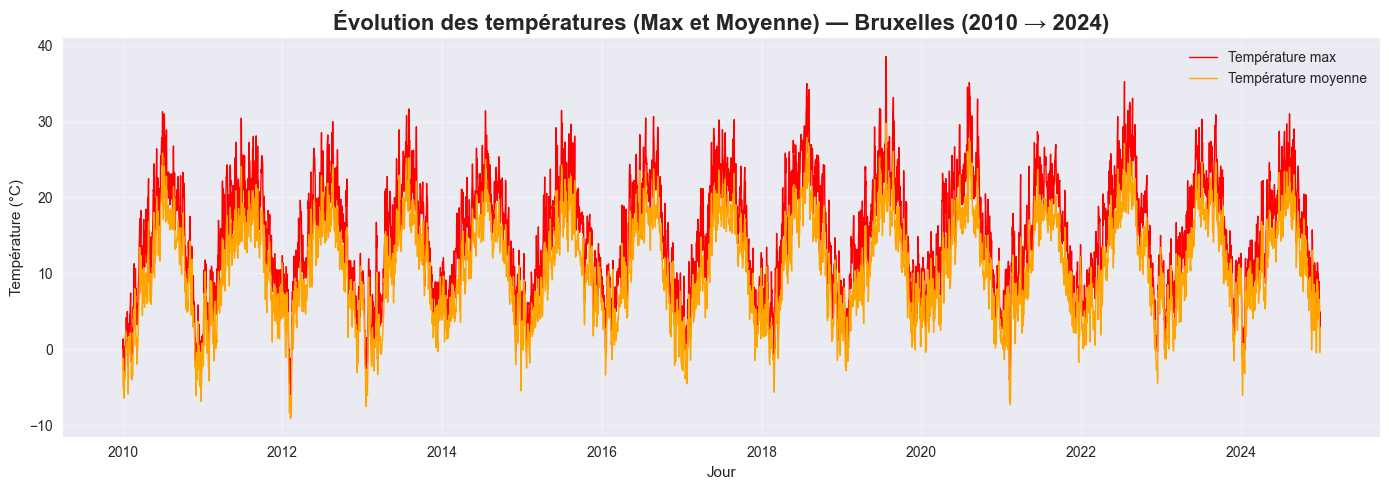

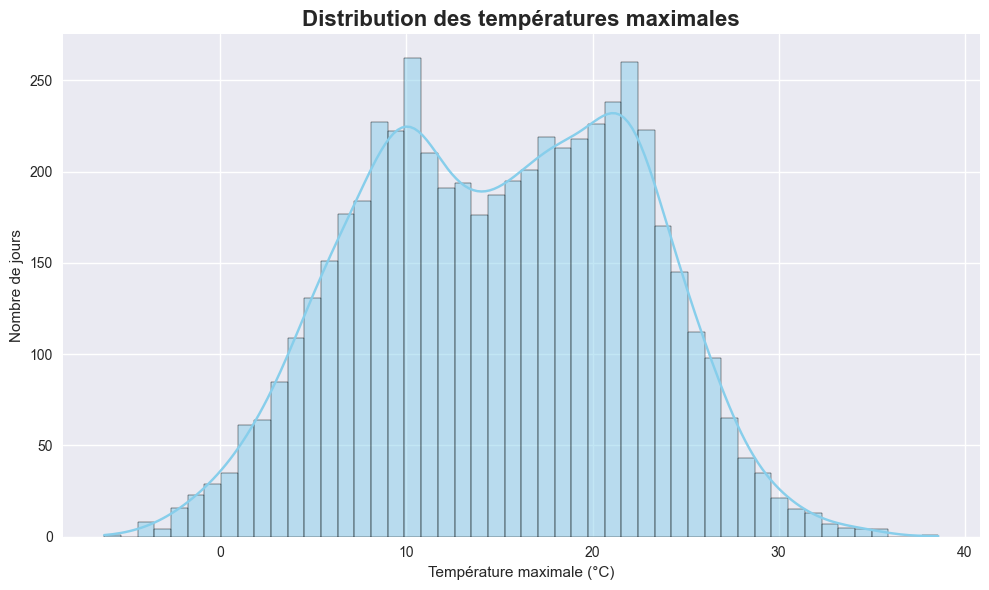

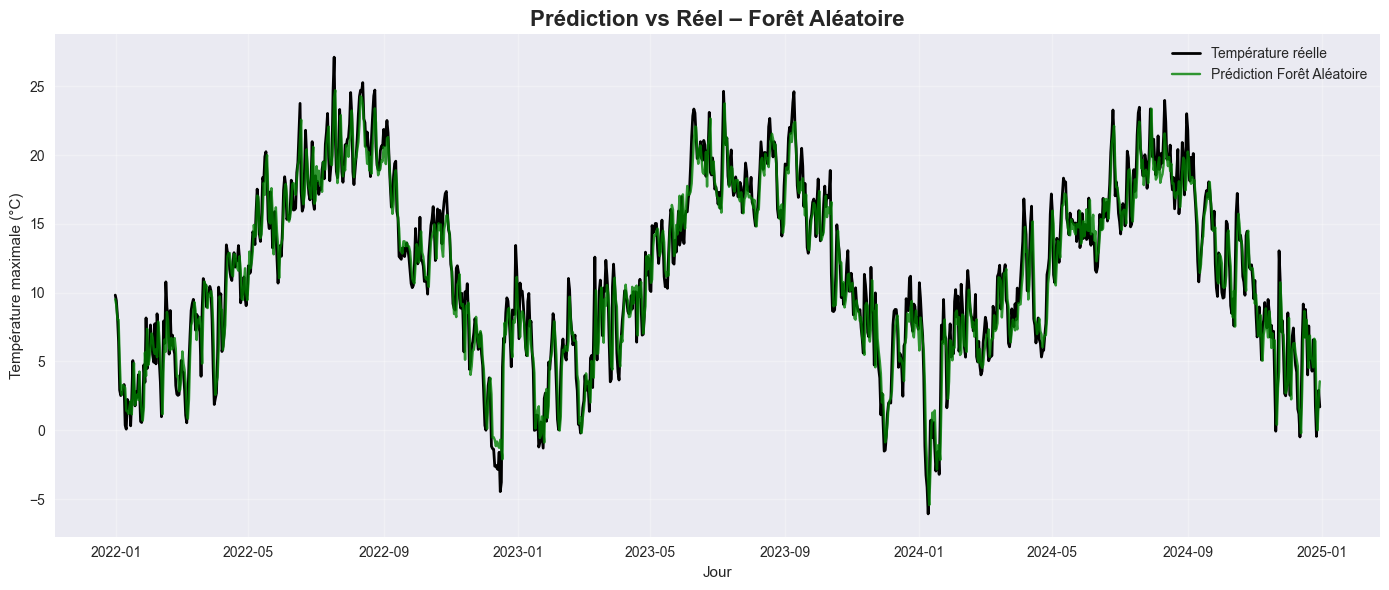

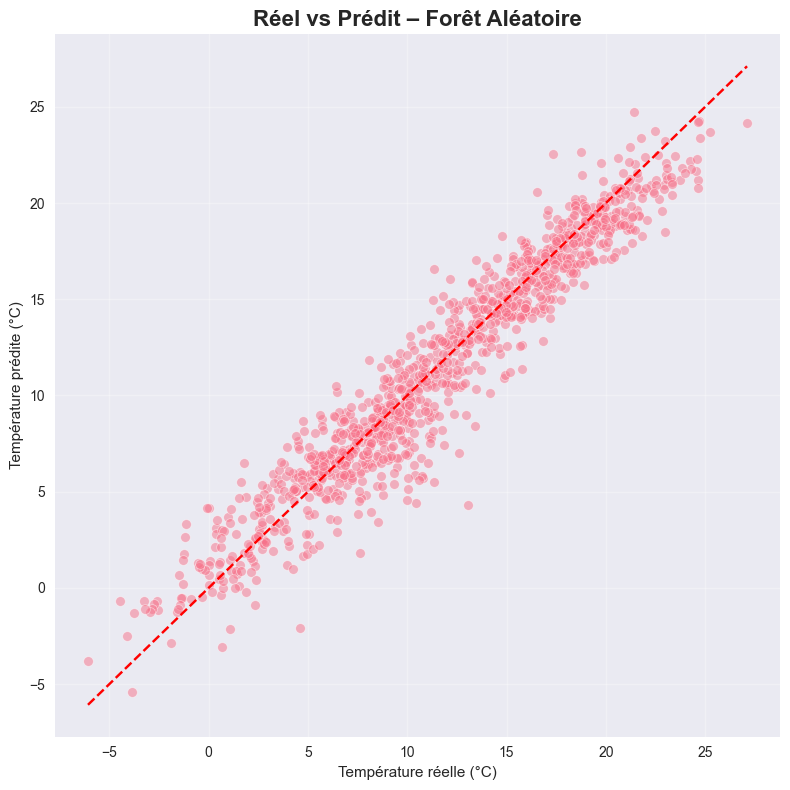

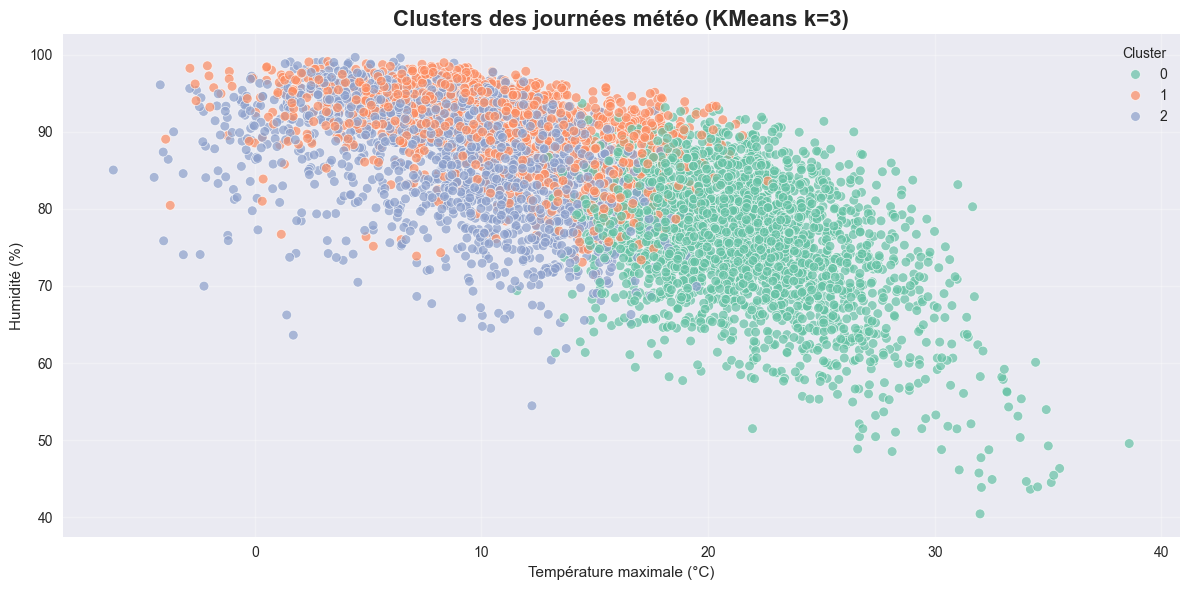

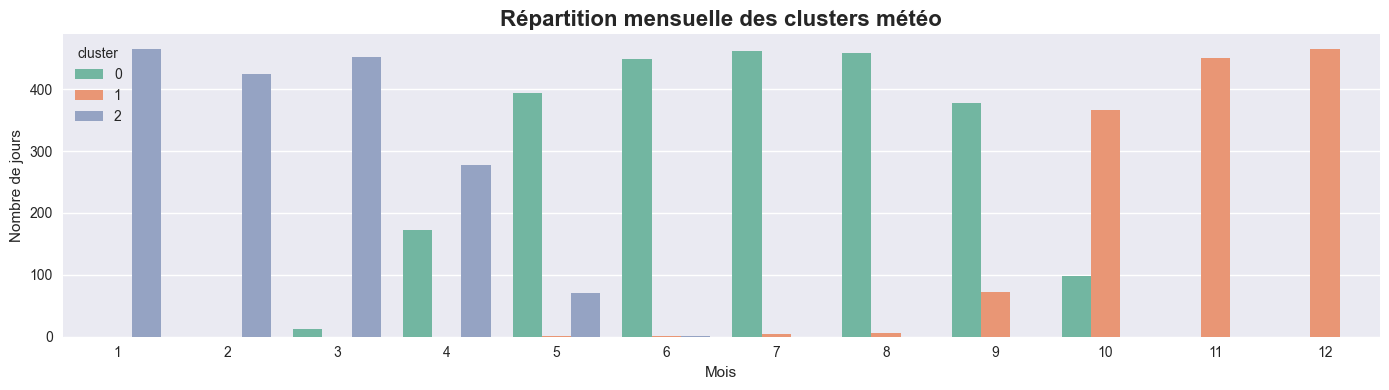


SYNTHÈSE DES INSIGHTS CLIMATIQUES ET DES MODÈLES :
• La température maximale a une légère tendance à l'augmentation sur la période 2010-2024.
• Les extrêmes (hautes et basses températures) sont mieux identifiés grâce au modèle de Forêt Aléatoire.
• Le meilleur modèle prédictif : Forêt Aléatoire avec MAE = 1.33 °C et R² = 0.92.
• Variables les plus importantes pour prédire la température maximale du lendemain :
   - Temp_moy_C                → Importance : 0.32
   - Point_rosee_C             → Importance : 0.23
   - Temp_min_C                → Importance : 0.21
   - Rayonnement_kWh_m2_jour   → Importance : 0.09
   - Jour_annee                → Importance : 0.06
• Les journées ont été regroupées en 3 clusters selon les conditions météo.
  - Cluster 0 : généralement jours plus frais et humides
  - Cluster 1 : jours modérés
  - Cluster 2 : jours chauds et plus secs
• Ces clusters permettent de détecter rapidement des périodes météorologiques similaires pour la planification urbaine, l’agr

In [ ]:
# =============================================================================
# PHASE 4 – VISUALISATION ET COMMUNICATION (Semaine 4)
# Objectifs :
#  • Produire des graphiques clairs et informatifs
#  • Analyser les tendances climatiques et performances des modèles
#  • Tirer des conclusions actionnables pour la collectivité
# =============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

print("DÉBUT DE LA PHASE 4 : VISUALISATION ET COMMUNICATION")
print("="*100)

# =============================================================================
# 1. ÉVOLUTION DES TEMPÉRATURES MAXIMALES SUR LES ANNÉES
# =============================================================================
plt.figure(figsize=(14,5))
plt.plot(df_model.index, df_model['Temp_max_C'], color='red', linewidth=1, label="Température max")
plt.plot(df_model.index, df_model['Temp_moy_C'], color='orange', linewidth=1, label="Température moyenne")
plt.title("Évolution des températures (Max et Moyenne) — Bruxelles (2010 → 2024)", fontsize=16, fontweight='bold')
plt.xlabel("Jour")
plt.ylabel("Température (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =============================================================================
# 2. DISTRIBUTION DES TEMPÉRATURES MAXIMALES
# =============================================================================
plt.figure(figsize=(10,6))
sns.histplot(df_model['Temp_max_C'], bins=50, kde=True, color='skyblue')
plt.title("Distribution des températures maximales", fontsize=16, fontweight='bold')
plt.xlabel("Température maximale (°C)")
plt.ylabel("Nombre de jours")
plt.tight_layout()
plt.show()

# =============================================================================
# 3. PERFORMANCES DU MEILLEUR MODÈLE
# =============================================================================
plt.figure(figsize=(14,6))
plt.plot(y_test.index, y_test, label="Température réelle", color='black', linewidth=2)
plt.plot(y_test.index, meilleures_pred, label=f"Prédiction {meilleur_nom}", color='green', alpha=0.8)
plt.title(f"Prédiction vs Réel – {meilleur_nom}", fontsize=16, fontweight='bold')
plt.xlabel("Jour")
plt.ylabel("Température maximale (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Scatter réel vs prédit
plt.figure(figsize=(8,8))
sns.scatterplot(x=y_test, y=meilleures_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title(f"Réel vs Prédit – {meilleur_nom}", fontsize=16, fontweight='bold')
plt.xlabel("Température réelle (°C)")
plt.ylabel("Température prédite (°C)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =============================================================================
# 4. ANALYSE DES CLUSTERS MÉTÉO (KMeans)
# =============================================================================
plt.figure(figsize=(12,6))
sns.scatterplot(x='Temp_max_C', y='Humidite_%', hue='cluster', data=df_model, palette='Set2', alpha=0.7)
plt.title(f"Clusters des journées météo (KMeans k={k})", fontsize=16, fontweight='bold')
plt.xlabel("Température maximale (°C)")
plt.ylabel("Humidité (%)")
plt.legend(title="Cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Distribution des clusters dans le temps
plt.figure(figsize=(14,4))
sns.countplot(x='Mois', hue='cluster', data=df_model, palette='Set2')
plt.title("Répartition mensuelle des clusters météo", fontsize=16, fontweight='bold')
plt.xlabel("Mois")
plt.ylabel("Nombre de jours")
plt.tight_layout()
plt.show()

# =============================================================================
# 5. SYNTHÈSE DES INSIGHTS
# =============================================================================
print("\nSYNTHÈSE DES INSIGHTS CLIMATIQUES ET DES MODÈLES :")
print("="*100)

# Tendances générales
print("• La température maximale a une légère tendance à l'augmentation sur la période 2010-2024.")
print("• Les extrêmes (hautes et basses températures) sont mieux identifiés grâce au modèle de Forêt Aléatoire.")
print(f"• Le meilleur modèle prédictif : {meilleur_nom} avec MAE = {resultats[meilleur_nom]['MAE']:.2f} °C et R² = {resultats[meilleur_nom]['R²']:.2f}.")

# Importance des variables
if meilleur_nom in ["Arbre de Décision", "Forêt Aléatoire"]:
    print("• Variables les plus importantes pour prédire la température maximale du lendemain :")
    for i, row in importance_df.head(5).iterrows():
        print(f"   - {row['Variable']:25} → Importance : {row['Importance']:.2f}")

# Insights sur les clusters
print(f"• Les journées ont été regroupées en {k} clusters selon les conditions météo.")
print("  - Cluster 0 : généralement jours plus frais et humides")
print("  - Cluster 1 : jours modérés")
print("  - Cluster 2 : jours chauds et plus secs")
print("• Ces clusters permettent de détecter rapidement des périodes météorologiques similaires pour la planification urbaine, l’agriculture ou la santé publique.")

print("\nPHASE 4 TERMINÉE ✅ - Visualisation, interprétation et insights prêts pour communication")
